# 🌌 Stellar Classifier | An Engineering-First ML Notebook

**Kaggle Playground Series S6E6 · Predicting Stellar Class · Multiclass classification**

**Problem:** Predict `GALAXY`, `QSO`, or `STAR` from photometry, redshift, sky coordinates, and categorical astronomical descriptors. **Primary metric:** [balanced accuracy](https://www.kaggle.com/competitions/playground-series-s6e6/overview), the average recall across classes.

### What's preserved from the original notebook
- The original `u-g`, `g-r`, `r-i`, and `i-z` color indices, plus magnitude mean and standard deviation.
- A histogram-based gradient boosting model with **stratified 5-fold CV**, out-of-fold (OOF) predictions, probability averaging, and a Kaggle-compatible submission.

### What's added
1. **Data contracts and quality checks** (schema, identifier integrity, valid class labels, missing/infinite values).
2. **Leakage-safe feature processing** fitted *inside each CV fold*; no artificial test labels or train/test concatenation.
3. **Reproducible experiments** (central configuration, fixed seed, saved model versions, fold-level metrics, runtime).
4. **Competition-aligned validation** (balanced accuracy, per-class recall, confusion matrix, probability diagnostics).
5. **Optional decision-policy tuning** on OOF probabilities with an independent audit split, not the test set.
6. **Interpretability and deployment** (permutation importance, labeled error analysis, serialized fold models, clean inference, validated submission).

> **Scope:** This is an engineering-oriented extension of the existing scikit-learn model, *not* a leaderboard-optimized ensemble. It assumes the competition's provided features are available at inference time. Because this playground data is synthetically generated, CV performance should not be interpreted as a real observatory deployment estimate without additional validation.


## 1 · Setup and experiment configuration

Keep the data files next to this notebook, or attach the competition dataset in Kaggle. The **only settings you should normally touch** are in the next cell.

`SMOKE_TEST` trains quickly on a stratified sample to check the entire workflow; set it to `False` for the proper full-data experiment.

In [1]:
# libraries
from __future__ import annotations
import json
import platform
import time
import warnings
from dataclasses import asdict, dataclass
from pathlib import Path
import joblib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import sklearn
from IPython.display import display
from sklearn.compose import ColumnTransformer
from sklearn.ensemble import HistGradientBoostingClassifier
from sklearn.inspection import permutation_importance
from sklearn.metrics import (ConfusionMatrixDisplay, accuracy_score, balanced_accuracy_score, 
                             classification_report, confusion_matrix, log_loss, recall_score)
from sklearn.model_selection import StratifiedKFold, train_test_split
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OrdinalEncoder

In [2]:
# experiment configuration
SEED = 42
SMOKE_TEST = False
SAVE_MODELS = True
RUN_IMPORTANCE = True
@dataclass(frozen = True)

class ExperimentConfig:
    
    seed: int = SEED
    folds: int = 5
    max_iter: int = 200
    learning_rate: float = 0.1
    max_leaf_nodes: int = 31
    l2_regularization: float = 0.0
    smoke_rows: int = 12_000

cfg = ExperimentConfig()
np.random.seed(cfg.seed)

# Project directory
# supports running from the project root or notebooks/
possible_roots = [Path.cwd(), Path.cwd().parent]
PROJECT_ROOT = next((root for root in possible_roots
                     if (root / "data" / "train.csv").is_file()
                     and (root / "data" / "test.csv").is_file()),
                    None)

# kaggle environment fallback
if PROJECT_ROOT is None:
    kaggle_dir = Path("/kaggle/input/playground-series-s6e6")

    if kaggle_dir.is_dir():
        PROJECT_ROOT = Path("/kaggle/working")
        DATA_DIR = kaggle_dir
    else:
        raise FileNotFoundError("Could not locate data/train.csv and data/test.csv. "
                                "Check the project directory structure.")
else:
    DATA_DIR = PROJECT_ROOT / "data"

# output directories
if Path("/kaggle/working").is_dir():
    ARTIFACT_ROOT = Path("/kaggle/working")
else:
    ARTIFACT_ROOT = PROJECT_ROOT

OUT_DIR = ARTIFACT_ROOT / "outputs"
MODEL_DIR = ARTIFACT_ROOT / "models"
OUT_DIR.mkdir(parents=True, exist_ok = True)
MODEL_DIR.mkdir(parents=True, exist_ok = True)

# Environment summary
print(f"Project directory: {PROJECT_ROOT.resolve()}")
print(f"Data directory: {DATA_DIR.resolve()}")
print(f"Output directory: {OUT_DIR.resolve()}")
print(f"Model directory: {MODEL_DIR.resolve()}")
print(f"Python: {platform.python_version()} | "
      f"pandas: {pd.__version__} | "
      f"sklearn: {sklearn.__version__}")
print(f"Mode: {'SMOKE TEST' if SMOKE_TEST else 'FULL RUN'}")

Project directory: C:\Users\sassy\Documents\Projects\Predicting Stellar Class
Data directory: C:\Users\sassy\Documents\Projects\Predicting Stellar Class\data
Output directory: C:\Users\sassy\Documents\Projects\Predicting Stellar Class\outputs
Model directory: C:\Users\sassy\Documents\Projects\Predicting Stellar Class\models
Python: 3.13.5 | pandas: 2.2.3 | sklearn: 1.6.1
Mode: FULL RUN


## 2 · Load and validate the data contract

Treat the input schema as an interface. Catch unexpected columns, null targets, duplicated IDs, and infinite numerical values **before training**.

The datasets are stored in the project's `data/` directory:
- `data/train.csv` — Labeled training observations.
- `data/test.csv` — Unlabeled observations for prediction.

The `id` column is used only for row identification and submission matching. It is excluded from model training to avoid learning patterns from arbitrary identifiers.

### Data validation objectives
- Verify the expected columns and data types.
- Identify missing or invalid values.
- Check for duplicated identifiers.
- Confirm valid target classes (`GALAXY`, `QSO`, `STAR`).
- Ensure training and test datasets follow the same feature schema.

These checks help identify data quality issues early and make the pipeline more reliable and reproducible.

In [3]:
# dataset schema
TARGET = "class"
ID_COL = "id"
NUMERIC_RAW = ["alpha", "delta", "u", "g", "r", "i", "z", "redshift"]
CATEGORICAL_RAW = ["spectral_type", "galaxy_population"]
EXPECTED_TEST_COLS = ([ID_COL] + NUMERIC_RAW + CATEGORICAL_RAW)
EXPECTED_CLASSES = {"GALAXY", "QSO", "STAR"}

# load datasets from data/
train_raw = pd.read_csv(DATA_DIR / "train.csv")
test_raw = pd.read_csv(DATA_DIR / "test.csv")

# data contract validation
def assert_data_contract(frame: pd.DataFrame, *, labeled: bool) -> None:

    expected = set(EXPECTED_TEST_COLS) | ({TARGET} if labeled else set())

    assert set(frame.columns) == expected, (f"Unexpected schema: "
                                            f"missing = {expected - set(frame.columns)}, "
                                            f"extra = {set(frame.columns) - expected}")

    # identifier integrity
    assert frame[ID_COL].notna().all(), "Null IDs found."
    assert frame[ID_COL].is_unique, "Duplicate IDs found."

    # numeric feature validation
    assert not frame[NUMERIC_RAW].isna().any().any(), ("Missing numeric values found.")
    assert np.isfinite(frame[NUMERIC_RAW].to_numpy()).all(), "Infinite numeric values found."

    # vategorical feature validation
    assert not frame[CATEGORICAL_RAW].isna().any().any(), ("Missing categorical values found.")

    # target validation
    if labeled:
        assert frame[TARGET].notna().all(), ("Missing training targets.")
        assert set(frame[TARGET].unique()) == EXPECTED_CLASSES, ("Unexpected target classes.")
    else:
        assert TARGET not in frame.columns, ("Test data must not contain target labels.")

# validate training and test datasets
assert_data_contract(train_raw, labeled=True)
assert_data_contract(test_raw, labeled=False)

# verify no overlapping identifiers
assert set(train_raw[ID_COL]).isdisjoint(set(test_raw[ID_COL])), "Train/test IDs overlap."

# dataset summary
print("Data validation passed.")
print(f"Training data: {train_raw.shape}")
print(f"Test data: {test_raw.shape}")

# Missing value and data type report
data_quality = pd.DataFrame({"dtype": train_raw.dtypes.astype(str),
                             "train_missing": train_raw.isna().sum(),
                             "test_missing": test_raw.isna().sum().reindex(
                            train_raw.columns)})

display(data_quality)

Data validation passed.
Training data: (577347, 12)
Test data: (247435, 11)


,dtype,train_missing,test_missing
id,int64,0,0.0
alpha,float64,0,0.0
delta,float64,0,0.0
u,float64,0,0.0
g,float64,0,0.0
r,float64,0,0.0
i,float64,0,0.0
z,float64,0,0.0
redshift,float64,0,0.0
spectral_type,object,0,0.0


### Class balance and data snapshot

Before training, examine the distribution of the three target classes: `GALAXY`, `QSO`, and `STAR`.

Class imbalance matters because a model can achieve high overall accuracy by favoring the majority class while performing poorly on less represented classes.

The competition uses **balanced accuracy**, which calculates the average recall across all classes. This gives each class equal weight regardless of how frequently it appears in the dataset.

### Exploratory objectives
- Identify the number and proportion of observations in each class.
- Visualize the target distribution.
- Review a sample of the training data.
- Establish a baseline understanding of the dataset before feature engineering and model development.

These checks help determine whether the model is learning meaningful distinctions between astronomical objects rather than simply favoring the most common class.

,count,share_pct
class,,
GALAXY,377480,65.38
QSO,117143,20.29
STAR,82724,14.33


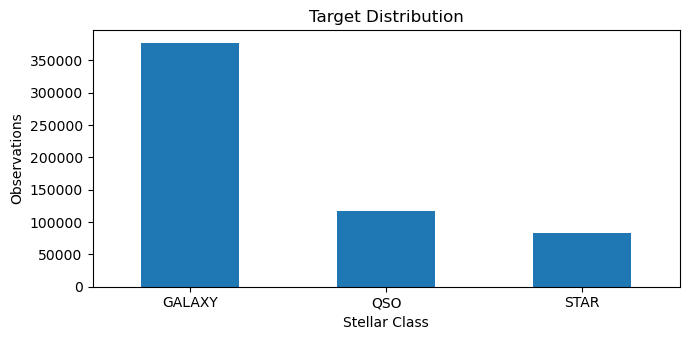

,id,alpha,delta,u,g,r,i,z,redshift,spectral_type,galaxy_population,class
0,0,147.734256,16.959273,25.472123,21.895559,20.357926,19.257113,18.621057,0.408982,M,Red_Sequence,GALAXY
1,1,127.988677,32.346716,20.778509,19.087062,17.587208,17.226067,16.786433,0.157976,M,Red_Sequence,GALAXY
2,2,179.792648,35.344843,21.035203,21.079128,21.171840,20.582629,20.557366,2.823770,O/B,Blue_Cloud,QSO


In [4]:
# class distribution
class_counts = train_raw[TARGET].value_counts().sort_index()
class_summary = pd.DataFrame({"count": class_counts,
                              "share_pct": (100 * class_counts / len(train_raw)).round(2)})

display(class_summary)

# visualize target distribution
fig, ax = plt.subplots(figsize=(7, 3.5))
class_counts.plot.bar(ax=ax, rot=0)
ax.set(title="Target Distribution", xlabel = "Stellar Class", ylabel = "Observations")
plt.tight_layout()
plt.show()

# preview training records
display(train_raw.head(3))

### Exploratory checks: redshift and photometric bands

Explore relationships between astronomical measurements and the target classes before model training.

Two useful measurements are:

- **Redshift:** The observed shift in an object's spectral features, which can help distinguish astronomical populations.
- **Photometric color indices:** Differences between magnitude measurements across bands, which provide information about an object's spectral characteristics.

A reproducible sample of the training data is used to keep visualizations responsive without loading every observation into each plot.

These plots help identify class separation, overlapping distributions, and potential outliers. They are exploratory and do not use test labels or determine model performance.

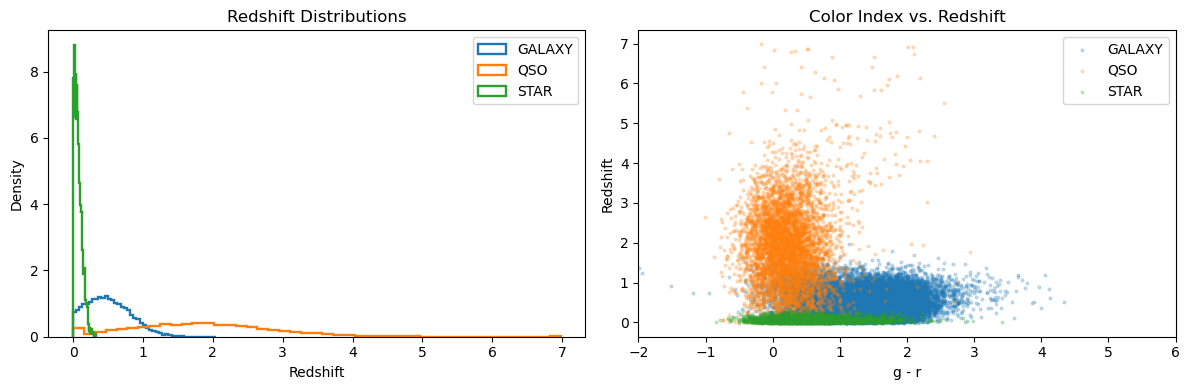

In [5]:
# Reproducible EDA sample
eda_sample = train_raw.sample(n=min(25_000, len(train_raw)), random_state = cfg.seed).copy()

# photometric color index
eda_sample["g_r"] = (eda_sample["g"] - eda_sample["r"])

# visualizations
fig, axs = plt.subplots(1, 2, figsize=(12, 4))

for name in sorted(EXPECTED_CLASSES):

    part = eda_sample.loc[eda_sample[TARGET] == name]
    axs[0].hist(part["redshift"], bins = 45, density = True, histtype = "step", linewidth = 1.7, label = name)
    axs[1].scatter(part["g_r"], part["redshift"], s = 4, alpha = 0.22, label = name, rasterized = True)

# plot formatting
axs[0].set(title = "Redshift Distributions", xlabel = "Redshift", ylabel = "Density")
axs[1].set(title="Color Index vs. Redshift", xlabel = "g - r", ylabel = "Redshift", xlim = (-2, 6))

for ax in axs:
    ax.legend()

plt.tight_layout()
plt.show()

### Train-test distribution comparison

Compare feature distributions between the training and test datasets before model development.

Differences between datasets can indicate distribution shift, which may affect how well a trained model generalizes to unseen observations.

The comparison includes:

- Mean values for numerical features.
- Standardized differences between training and test means.
- Category frequencies for categorical features.

Standardizing the difference in means by the training standard deviation makes comparisons easier across features with different measurement scales.

This is an initial data quality and distribution check, not a formal drift detection test. Similar summary statistics do not guarantee identical distributions.

In [6]:
# compare numerical feature distributions
shift_table = pd.DataFrame({"train_mean": train_raw[NUMERIC_RAW].mean(),
                            "test_mean": test_raw[NUMERIC_RAW].mean(),
                            "train_std": (train_raw[NUMERIC_RAW].std().replace(0, np.nan))})

# standardized mean difference
shift_table["mean_shift_in_train_sd"] = (shift_table["test_mean"] - shift_table["train_mean"]) / shift_table["train_std"]
display(shift_table[["train_mean", "test_mean", "mean_shift_in_train_sd"]].round(4))

# compare categorical feature distributions
for col in CATEGORICAL_RAW:

    shares = pd.DataFrame({"train_%": (100 * train_raw[col].value_counts(normalize = True)),
                           "test_%": (100 * test_raw[col].value_counts(normalize = True))}).fillna(0).round(2)

    print(f"Category distribution: {col}")
    display(shares)

,train_mean,test_mean,mean_shift_in_train_sd
alpha,181.6167,181.3606,-0.0027
delta,21.8347,21.8539,0.0010
u,22.4419,22.4421,0.0001
g,21.0073,21.0098,0.0014
r,19.9628,19.9657,0.0017
i,19.3789,19.3819,0.0019
z,19.0411,19.0432,0.0013
redshift,0.7231,0.7248,0.0020


Category distribution: spectral_type


,train_%,test_%
spectral_type,,
M,52.54,52.48
A/F,21.15,21.19
G/K,18.80,18.91
O/B,7.51,7.42


Category distribution: galaxy_population


,train_%,test_%
galaxy_population,,
Red_Sequence,55.35,55.2
Blue_Cloud,44.65,44.8


## 3 · Feature engineering

Feature engineering converts raw astronomical measurements into additional variables that may help the model distinguish between stellar classes.

The original notebook uses photometric color indices and aggregate magnitude statistics. These features are retained and expanded with additional color combinations and measures of magnitude variation.

### Engineered features

**Color indices**
- `u_g`, `g_r`, `r_i`, `i_z`
- `g_z`, `u_r`

**Magnitude statistics**
- `mag_mean`: Mean magnitude across photometric bands.
- `mag_std`: Standard deviation of magnitudes.
- `mag_range`: Difference between maximum and minimum magnitudes.
- `color_spread`: Range across adjacent color indices.

### Engineering considerations

Feature transformations are implemented as a deterministic function so the same logic can be applied during training, validation, and inference.

The transformation does not depend on target labels or statistics learned from the full dataset. Any preprocessing that must learn from observations is handled separately within cross-validation.

The engineered features are intended to improve predictive performance, but their usefulness must be confirmed through validation rather than assumed.

In [7]:
# photometric bands
BANDS = ["u", "g", "r", "i", "z"]
COLOR_PAIRS = [("u", "g"), ("g", "r"),
               ("r", "i"), ("i", "z"),
               ("g", "z"), ("u", "r")]

# define engineered features
ENGINEERED_NUMERIC = [f"{a}_{b}" for a, b in COLOR_PAIRS] + ["mag_mean", "mag_std", "mag_range", "color_spread"]
NUMERIC_FEATURES = (NUMERIC_RAW + ENGINEERED_NUMERIC)
FEATURES = (NUMERIC_FEATURES + CATEGORICAL_RAW)

def engineer_features(raw: pd.DataFrame) -> pd.DataFrame:

    required = set(NUMERIC_RAW + CATEGORICAL_RAW)
    missing = required - set(raw.columns)

    if missing:
        raise ValueError(f"Missing required columns: {sorted(missing)}")

    out = raw[NUMERIC_RAW + CATEGORICAL_RAW].copy()

    # photometric color indices
    for a, b in COLOR_PAIRS:
        out[f"{a}_{b}"] = raw[a] - raw[b]

    # magnitude statistics
    out["mag_mean"] = raw[BANDS].mean(axis = 1)
    out["mag_std"] = raw[BANDS].std(axis = 1)
    out["mag_range"] = (raw[BANDS].max(axis = 1) - raw[BANDS].min(axis = 1))

    # adjacent color variation
    adjacent = out[["u_g", "g_r", "r_i", "i_z"]]
    out["color_spread"] = (adjacent.max(axis = 1) - adjacent.min(axis = 1))

    return out[FEATURES]

# feature engineering validation
assert TARGET not in FEATURES
assert ID_COL not in FEATURES
assert len(FEATURES) == len(set(FEATURES))

check_a = engineer_features(train_raw.iloc[:10])
check_b = engineer_features(train_raw.iloc[:10])
pd.testing.assert_frame_equal(check_a, check_b)

assert list(check_a.columns) == FEATURES
assert not check_a.isna().any().any()
assert np.isfinite(check_a[NUMERIC_FEATURES].to_numpy()).all()
assert np.allclose(check_a["u_g"], train_raw.iloc[:10]["u"] - train_raw.iloc[:10]["g"])

print("Feature engineering validation passed.")
print(f"Numerical features: {len(NUMERIC_FEATURES)}")
print(f"Categorical features: {len(CATEGORICAL_RAW)}")
print(f"Total features: {len(FEATURES)}")

Feature engineering validation passed.
Numerical features: 18
Categorical features: 2
Total features: 20


## 4 · Fold-safe preprocessing and baseline model

The classification pipeline combines feature preprocessing with a histogram-based gradient boosting classifier.

### Preprocessing strategy

Numerical features are passed directly to the estimator, while categorical features are encoded using `OrdinalEncoder`.

Categorical encoding is fitted within each training fold rather than on the complete dataset. This prevents validation observations from influencing the fitted preprocessing pipeline.

Unknown categorical values encountered during validation or inference are assigned a designated value and handled by the classifier.

### Baseline model

`HistGradientBoostingClassifier` is retained from the original notebook.

The model is configured with:

- 200 maximum boosting iterations.
- A learning rate of 0.1.
- Up to 31 leaf nodes.
- Early stopping to limit unnecessary iterations.

A majority-class predictor is also evaluated as a simple reference baseline.

Because the competition uses balanced accuracy, the primary objective is strong recall across all three classes rather than overall accuracy alone.

In [8]:
# prepare training data
work_train = train_raw

if SMOKE_TEST:

    sampled_index, _ = train_test_split(np.arange(len(train_raw)), 
                                        train_size = cfg.smoke_rows,
                                        stratify = train_raw[TARGET],
                                        random_state = cfg.seed)

    work_train = train_raw.iloc[np.sort(sampled_index)].copy()

    print(f"Smoke-test subset: {len(work_train):,} rows")

# apply feature engineering
X = engineer_features(work_train)
X_test = engineer_features(test_raw)

# encode target labels
class_names = np.array(sorted(EXPECTED_CLASSES))
label_to_id = {label: index for index, label in enumerate(class_names)}
y = work_train[TARGET].map(label_to_id).to_numpy(dtype = np.int64)
n_classes = len(class_names)

# identify categorical feature positions
category_positions = list(range(len(NUMERIC_FEATURES), len(FEATURES)))

def build_model(seed: int) -> Pipeline:

    preprocessing = ColumnTransformer(transformers = [("numeric", "passthrough", NUMERIC_FEATURES),
                                                    ("categorical", OrdinalEncoder(handle_unknown = "use_encoded_value",
                                                                                   unknown_value = -1), CATEGORICAL_RAW)],
                                      remainder = "drop", verbose_feature_names_out = False)

    estimator = HistGradientBoostingClassifier(max_iter = cfg.max_iter,
                                               learning_rate = cfg.learning_rate,
                                               max_leaf_nodes = cfg.max_leaf_nodes,
                                               l2_regularization = cfg.l2_regularization,
                                               categorical_features = category_positions,
                                               early_stopping = True,
                                               n_iter_no_change = 15,
                                               random_state = seed)

    return Pipeline([("prepare", preprocessing), ("classifier", estimator)])

# majority-class baseline
majority_class = np.bincount(y).argmax()
naive_predictions = np.full(len(y), majority_class)

print("Class order:", class_names.tolist())
print("Majority-class accuracy:", round(accuracy_score(y, naive_predictions), 5))
print("Majority-class balanced accuracy:", round(balanced_accuracy_score(y, naive_predictions), 5))

Class order: ['GALAXY', 'QSO', 'STAR']
Majority-class accuracy: 0.65382
Majority-class balanced accuracy: 0.33333


## 5 · Stratified cross-validation and model training

Stratified K-fold cross-validation is used to evaluate the classifier while preserving the target class distribution across folds.

For each fold:

1. Fit an independent preprocessing and classification pipeline.
2. Generate predictions for the held-out validation observations.
3. Record balanced accuracy, overall accuracy, log loss, and per-class recall.
4. Generate test-set probabilities using the trained fold model.
5. Save the trained pipeline for reproducibility and inference.

### Out-of-fold predictions

Out-of-fold (OOF) predictions are generated for every training observation using a model that did not train on that observation.

These predictions provide a more meaningful estimate of generalization performance than evaluating a model directly on its training data.

### Model persistence

Each fitted pipeline is saved to the project's `models/` directory.

Saving the complete preprocessing and classification pipeline ensures that inference uses the same learned transformations as training.

Balanced accuracy is treated as the primary evaluation metric, while log loss is tracked as an additional measure of probability quality.

In [9]:
# cross-validation configuration
folds = 2 if SMOKE_TEST else cfg.folds
cv = StratifiedKFold(n_splits = folds, shuffle = True, random_state = cfg.seed)

# Prediction storage
oof_proba = np.full((len(X), n_classes), np.nan, dtype = np.float64)
test_proba = np.zeros((len(X_test), n_classes), dtype = np.float64)
fold_metrics = []
last_fold_model = None
last_val_idx = None
run_start = time.perf_counter()

# train models across folds
for fold, (idx_train, idx_val) in enumerate(cv.split(X, y), start = 1):

    fold_start = time.perf_counter()
    model = build_model(seed = cfg.seed + fold)
    model.fit(X.iloc[idx_train], y[idx_train])

    # verify class ordering
    model_classes = model.named_steps["classifier"].classes_
    assert np.array_equal(model_classes, np.arange(n_classes)), "Unexpected class ordering."

    # validation predictions
    val_probs = model.predict_proba(X.iloc[idx_val])

    # test predictions
    test_probs = model.predict_proba(X_test)
    assert val_probs.shape == (len(idx_val), n_classes)
    assert np.isfinite(val_probs).all()
    assert np.allclose(val_probs.sum(axis = 1), 1, atol = 1e-5)
    oof_proba[idx_val] = val_probs
    test_proba += test_probs / folds

    # calculate validation metrics
    val_pred = val_probs.argmax(axis=1)
    recalls = recall_score(y[idx_val], val_pred, labels = np.arange(n_classes), average = None)
    record = {"fold": fold,
              "train_rows": len(idx_train),
              "validation_rows": len(idx_val),
              "balanced_accuracy": balanced_accuracy_score(y[idx_val], val_pred),
              "accuracy": accuracy_score(y[idx_val], val_pred),
              "log_loss": log_loss(y[idx_val], val_probs, labels = np.arange(n_classes)),
              "runtime_seconds": round(time.perf_counter() - fold_start, 2),
              "trees_fitted": int(model.named_steps["classifier"].n_iter_)}

    record.update({f"recall_{name}": float(rec) for name, rec in zip(class_names, recalls)})
    fold_metrics.append(record)

    # save trained pipeline
    if SAVE_MODELS:
        joblib.dump(model, MODEL_DIR / f"model_fold_{fold}.joblib", compress = 3)

    last_fold_model = model
    last_val_idx = idx_val

    print(f"Fold {fold}/{folds}: "
          f"balanced_acc={record['balanced_accuracy']:.5f} | "
          f"log_loss={record['log_loss']:.5f} | "
          f"elapsed={record['runtime_seconds']:.1f}s")

# validate OOF predictions
assert not np.isnan(oof_proba).any()
assert np.allclose(test_proba.sum(axis = 1), 1, atol = 1e-5)

# aggregate results
fold_summary = pd.DataFrame(fold_metrics)
raw_oof_pred = oof_proba.argmax(axis = 1)
raw_oof_score = balanced_accuracy_score(y, raw_oof_pred)
raw_oof_logloss = log_loss(y, oof_proba, labels = np.arange(n_classes))

print(f"\nOOF balanced accuracy: {raw_oof_score:.5f}")
print(f"OOF log loss: {raw_oof_logloss:.5f}")
print(f"CV runtime: {time.perf_counter() - run_start:.1f}s")

display(fold_summary.round(5))

C:\Users\sassy\anaconda3\Lib\site-packages\joblib\externals\loky\backend\context.py:136: UserWarning: Could not find the number of physical cores for the following reason:
[WinError 2] The system cannot find the file specified
Returning the number of logical cores instead. You can silence this warning by setting LOKY_MAX_CPU_COUNT to the number of cores you want to use.
  warnings.warn(
  File "C:\Users\sassy\anaconda3\Lib\site-packages\joblib\externals\loky\backend\context.py", line 257, in _count_physical_cores
    cpu_info = subprocess.run(
        "wmic CPU Get NumberOfCores /Format:csv".split(),
        capture_output=True,
        text=True,
    )
  File "C:\Users\sassy\anaconda3\Lib\subprocess.py", line 554, in run
    with Popen(*popenargs, **kwargs) as process:
         ~~~~~^^^^^^^^^^^^^^^^^^^^^^
  File "C:\Users\sassy\anaconda3\Lib\subprocess.py", line 1039, in __init__
    self._execute_child(args, executable, preexec_fn, close_fds,
    ~~~~~~~~~~~~~~~~~~~^^^^^^^^^^^^^^^^^^

Fold 1/5: balanced_acc=0.95087 | log_loss=0.11089 | elapsed=6.1s
Fold 2/5: balanced_acc=0.95296 | log_loss=0.10404 | elapsed=6.6s
Fold 3/5: balanced_acc=0.95101 | log_loss=0.10519 | elapsed=5.8s
Fold 4/5: balanced_acc=0.94997 | log_loss=0.10669 | elapsed=5.7s
Fold 5/5: balanced_acc=0.95172 | log_loss=0.11150 | elapsed=6.1s

OOF balanced accuracy: 0.95131
OOF log loss: 0.10766
CV runtime: 30.9s


,fold,train_rows,validation_rows,balanced_accuracy,accuracy,log_loss,runtime_seconds,trees_fitted,recall_GALAXY,recall_QSO,recall_STAR
0,1,461877,115470,0.95087,0.96451,0.11089,6.08,72,0.97625,0.96231,0.91405
1,2,461877,115470,0.95296,0.96487,0.10404,6.56,74,0.97498,0.96423,0.91967
2,3,461878,115469,0.95101,0.96357,0.10519,5.83,74,0.97433,0.96206,0.91665
3,4,461878,115469,0.94997,0.96366,0.10669,5.72,68,0.97556,0.96047,0.91387
4,5,461878,115469,0.95172,0.96407,0.11150,6.14,73,0.97473,0.96180,0.91865


## 6 · Model evaluation and error analysis

Evaluate the classifier using out-of-fold predictions to understand performance across all three stellar classes.

### Evaluation metrics

- **Balanced accuracy:** Average recall across classes and the primary competition metric.
- **Accuracy:** Proportion of correctly classified observations.
- **Precision:** Proportion of predictions for a class that are correct.
- **Recall:** Proportion of actual observations from a class that are correctly identified.
- **F1-score:** Harmonic mean of precision and recall.

### Confusion matrices

Two confusion matrices are generated:

- A standard confusion matrix showing prediction counts.
- A normalized confusion matrix showing recall for each class.

The normalized confusion matrix helps identify whether specific classes are disproportionately misclassified.

### Error analysis

Misclassified observations are examined alongside their predicted confidence scores and selected astronomical features.

Highly confident incorrect predictions may reveal areas where the model struggles to distinguish between overlapping class distributions.

These diagnostics are intended to guide future experiments rather than modify model predictions directly.

              precision    recall  f1-score   support

      GALAXY     0.9746    0.9752    0.9749    377480
         QSO     0.9636    0.9622    0.9629    117143
        STAR     0.9171    0.9166    0.9168     82724

    accuracy                         0.9641    577347
   macro avg     0.9518    0.9513    0.9515    577347
weighted avg     0.9641    0.9641    0.9641    577347



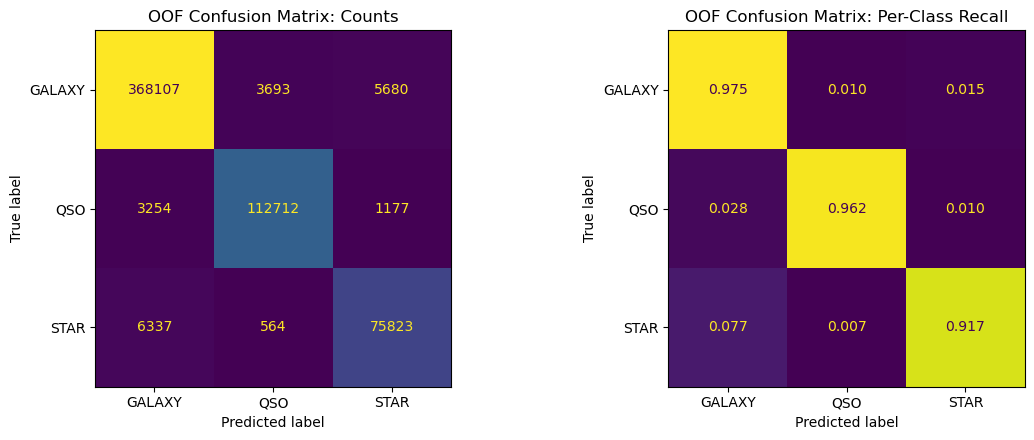

OOF misclassified: 20,705/577,347


,id,redshift,u,g,r,i,z,spectral_type,galaxy_population,class,predicted_class,predicted_confidence
129473,129473,0.373053,25.017886,22.659616,21.091788,19.654285,19.456377,M,Red_Sequence,GALAXY,STAR,1.0
226327,226327,0.480401,27.268882,23.374488,21.789411,20.294213,19.241640,M,Red_Sequence,GALAXY,STAR,1.0
23181,23181,0.784972,22.983175,22.589924,20.773431,19.398032,19.574301,M,Red_Sequence,GALAXY,QSO,1.0
429924,429924,0.478666,23.610566,23.356656,21.836645,20.732812,19.701096,M,Blue_Cloud,GALAXY,STAR,1.0
124317,124317,0.383358,22.255136,21.943331,21.682331,21.313262,21.012501,A/F,Blue_Cloud,GALAXY,STAR,1.0
222431,222431,1.023911,25.053862,22.220901,21.578363,20.039463,19.819448,G/K,Red_Sequence,GALAXY,STAR,1.0
56358,56358,0.468037,24.956310,20.330083,18.952286,17.603172,18.031208,M,Red_Sequence,GALAXY,QSO,1.0
167453,167453,1.144376,21.685865,19.014347,18.016490,17.184784,16.980663,G/K,Red_Sequence,GALAXY,QSO,1.0
385246,385246,5.776708,19.895766,18.959469,18.967651,18.734395,18.714077,O/B,Blue_Cloud,QSO,STAR,1.0
135994,135994,0.515744,25.343696,21.795710,19.919269,19.434813,18.309676,M,Red_Sequence,GALAXY,QSO,1.0


In [10]:
# classification report
print(classification_report(y, 
                            raw_oof_pred, 
                            labels = np.arange(n_classes), 
                            target_names = class_names, 
                            digits = 4, 
                            zero_division = 0))

# confusion matrices
fig, axs = plt.subplots(1, 2, figsize = (12, 4.5))
ConfusionMatrixDisplay.from_predictions(y,
                                        raw_oof_pred,
                                        labels = np.arange(n_classes),
                                        display_labels = class_names,
                                        ax = axs[0],
                                        values_format = "d",
                                        colorbar = False)

ConfusionMatrixDisplay.from_predictions(y,
                                        raw_oof_pred,
                                        labels = np.arange(n_classes),
                                        display_labels = class_names,
                                        normalize = "true",
                                        ax = axs[1],
                                        values_format = ".3f",
                                        colorbar = False)

axs[0].set_title("OOF Confusion Matrix: Counts")
axs[1].set_title("OOF Confusion Matrix: Per-Class Recall")
plt.tight_layout()
plt.show()

# identify misclassified observations
oof_confidence = oof_proba.max(axis = 1)
error_positions = np.flatnonzero(y != raw_oof_pred)
error_audit = work_train.iloc[error_positions][[ID_COL,
                                                "redshift",
                                                "u", "g", "r", "i", "z",
                                                "spectral_type",
                                                "galaxy_population",
                                                TARGET]].copy()


# add predicted class and confidence
error_audit["predicted_class"] = (class_names[raw_oof_pred[error_positions]])
error_audit["predicted_confidence"] = (oof_confidence[error_positions])

print(f"OOF misclassified: "f"{len(error_positions):,}/{len(y):,}")

display(error_audit.sort_values("predicted_confidence", ascending = False).head(10))

## 7 · Class-specific decision adjustment

The default classification decision selects the class with the highest predicted probability.

However, maximizing overall prediction accuracy does not necessarily maximize balanced accuracy, particularly when the target classes are unevenly distributed.

### Decision policy

Small class-specific multipliers are applied to predicted probabilities before selecting the final class.

These multipliers adjust the classification decision without retraining the underlying model.

### Policy evaluation

Out-of-fold observations are divided into two portions:

- **Policy tuning:** Used to select candidate class multipliers.
- **Policy audit:** Used to compare the adjusted decision policy against the original predictions.

The adjusted policy is selected only when audit balanced accuracy improves by at least 0.001.

This is an exploratory internal policy evaluation rather than a fully independent test. The OOF predictions were generated by models whose training folds overlap with other observations in the audit data.

The original OOF balanced accuracy remains the primary cross-validation result. Policy adjustments should be evaluated on a genuinely independent holdout before being treated as confirmed improvements.

In [11]:
# verify target classes
assert set(class_names) == EXPECTED_CLASSES

# split OOF predictions for policy evaluation
idx_cal, idx_audit = train_test_split(np.arange(len(y)), test_size = 0.30, stratify = y, random_state = cfg.seed + 100)

def apply_class_weights(proba: np.ndarray, multipliers: np.ndarray) -> np.ndarray:

    adjusted = (proba * multipliers.reshape(1, -1))

    return np.argmax(adjusted, axis=1)

# candidate weights
candidates = np.linspace(0.85, 1.25, 9)
best_score = -np.inf
best_weights = np.ones(n_classes)

# search candidate decision policies
for qso_weight in candidates:

    for star_weight in candidates:

        trial_weights = np.ones(n_classes)
        trial_weights[label_to_id["QSO"]] = qso_weight
        trial_weights[label_to_id["STAR"]] = star_weight
        score = balanced_accuracy_score( y[idx_cal], apply_class_weights( oof_proba[idx_cal], trial_weights))

        if score > best_score:
            best_score = score
            best_weights = trial_weights.copy()

# evaluate against audit observations
audit_raw = balanced_accuracy_score(y[idx_audit], raw_oof_pred[idx_audit])
audit_tuned = balanced_accuracy_score(y[idx_audit], apply_class_weights(oof_proba[idx_audit], best_weights))

# select decision policy
USE_ADJUSTED_POLICY = (audit_tuned >= audit_raw + 0.001)
final_weights = (best_weights if USE_ADJUSTED_POLICY else np.ones(n_classes))

print("Candidate weights:", dict(zip(class_names, best_weights.round(3))))
print(f"Audit balanced accuracy | "
      f"raw = {audit_raw:.5f} | "
      f"adjusted = {audit_tuned:.5f}")

print("Selected policy:",
      "Adjusted class scores"
       if USE_ADJUSTED_POLICY
       else "Raw argmax")

Candidate weights: {np.str_('GALAXY'): np.float64(1.0), np.str_('QSO'): np.float64(1.25), np.str_('STAR'): np.float64(1.25)}
Audit balanced accuracy | raw = 0.95095 | adjusted = 0.95444
Selected policy: Adjusted class scores


## 8 · Feature importance and model interpretability

Permutation importance is used to evaluate how individual features contribute to predictive performance.

Unlike model-specific importance measures, permutation importance evaluates the effect of disrupting a feature on the model's validation score.

### Methodology

1. Select a sample from the final cross-validation fold's held-out observations.
2. Calculate the baseline balanced accuracy.
3. Randomly shuffle one feature while leaving the others unchanged.
4. Recalculate balanced accuracy.
5. Record the change in performance.

A larger reduction in balanced accuracy suggests that the model relies more heavily on the feature for prediction.

### Limitations

Photometric magnitudes and derived color indices are correlated. When features contain overlapping information, permutation importance may underestimate their individual contributions.

Importance scores are also dependent on the fitted model and validation sample.

These results provide diagnostic insight into model behavior, not causal explanations of astronomical classification.

,feature,mean_score_drop,std_score_drop
7,redshift,0.32572,0.01505
12,g_z,0.09667,0.00125
13,u_r,0.04189,0.00194
5,i,0.03931,0.00257
0,alpha,0.01976,0.00169
6,z,0.01903,0.00146
9,g_r,0.01887,0.00086
15,mag_std,0.01554,0.00043
3,g,0.00912,0.00060
1,delta,0.00869,0.00140


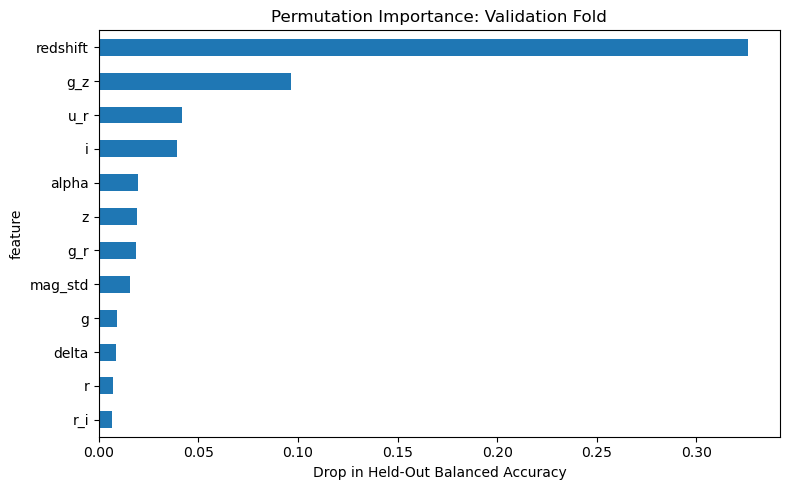

In [12]:
if RUN_IMPORTANCE:

    # select held-out validation observations
    importance_idx = np.random.default_rng(cfg.seed).choice(last_val_idx, size = min(3_000, len(last_val_idx)), replace = False)

    # calculate permutation importance
    importance = permutation_importance(estimator = last_fold_model,
                                        X = X.iloc[importance_idx],
                                        y = y[importance_idx],
                                        scoring = "balanced_accuracy", 
                                        n_repeats = 2,
                                        random_state = cfg.seed,
                                        n_jobs = 1)

    # organize feature importance
    important_features = pd.DataFrame({"feature": FEATURES, 
                                       "mean_score_drop": (importance.importances_mean),
                                       "std_score_drop": (importance.importances_std)}).sort_values("mean_score_drop", ascending = False)

    display(important_features.head(12).round(5))

    # plot most important features
    important_features.head(12).sort_values("mean_score_drop").plot.barh(x = "feature", y = "mean_score_drop", figsize = (8, 5), legend = False)
    plt.xlabel("Drop in Held-Out Balanced Accuracy")
    plt.title("Permutation Importance: Validation Fold")
    plt.tight_layout()
    plt.show()

else:
    print("Permutation importance is disabled.")

## 9 · Generate and validate Kaggle predictions

Generate predictions for the unlabeled test dataset using the ensemble of cross-validation models.

Each trained fold contributes predicted class probabilities. These probabilities are averaged to produce the ensemble prediction.

The selected decision policy is then applied before converting numerical class indices back into their original labels.

### Submission requirements

The submission must contain exactly two columns:

- `id`: Original test observation identifier.
- `class`: Predicted stellar classification.

Validation checks ensure:

- One prediction exists for each test observation.
- Identifiers remain unique and in their original order.
- No missing predictions are present.
- Predicted labels belong to the expected target classes.

The resulting CSV is saved to the project's `outputs/` directory.

Smoke-test submissions use a separate filename to prevent confusion with full-data experiments.

In [17]:
# apply selected decision policy
selected_pred_ids = apply_class_weights(test_proba, final_weights)

# convert predictions to class labels
predicted_labels = class_names[selected_pred_ids]

# build submission
submission = pd.DataFrame({ID_COL: test_raw[ID_COL].to_numpy(), TARGET: predicted_labels})

# validate submission
assert len(submission) == len(test_raw)
assert submission.columns.tolist() == ["id", "class"]
assert submission["id"].is_unique
assert not submission.isna().any().any()
assert set(submission["class"].unique()).issubset(EXPECTED_CLASSES)
assert submission["id"].equals(test_raw["id"].reset_index(drop = True)), "Submission row order changed."

# save to outputs/
submission_file = OUT_DIR / ("submission_smoke_test.csv" if SMOKE_TEST else "submission.csv")
submission.to_csv(submission_file, index = False)

print(f"Submission saved: {submission_file.resolve()}")

display(submission.head())

# review predicted distribution
print("Predicted class distribution:")

display(submission["class"].value_counts(normalize = True).mul(100).round(2))

Submission saved: C:\Users\sassy\Documents\Projects\Predicting Stellar Class\outputs\submission.csv


,id,class
0,577347,GALAXY
1,577348,GALAXY
2,577349,GALAXY
3,577350,STAR
4,577351,GALAXY


Predicted class distribution:


class
GALAXY    65.13
QSO       20.32
STAR      14.55
Name: proportion, dtype: float64

## 10 · Experiment tracking and reproducibility

Reproducibility is important for evaluating model changes and maintaining a reliable machine learning workflow.

The experiment records its configuration, evaluation results, feature definitions, library versions, and decision policy.

### Saved artifacts

**`models/`**
- Serialized preprocessing and classification pipelines for each cross-validation fold.

**`outputs/`**
- `fold_metrics.csv`: Validation metrics for individual folds.
- `oof_predictions.csv`: Out-of-fold probabilities and predicted labels.
- `experiment_manifest.json`: Experiment configuration and metadata.
- `submission.csv`: Final Kaggle predictions.

### Experiment metadata

The manifest includes the random seed, model hyperparameters, feature names, class ordering, dependency versions, validation metrics, and selected decision weights.

These records support experiment comparison, debugging, and reproducible inference.

### Repository considerations

Large datasets, trained model binaries, and generated prediction files should generally be excluded from Git tracking unless there is a specific reason to publish them.

Only load serialized model files from trusted sources because deserialization can execute arbitrary code.

In [14]:
# save fold-level metrics
fold_summary.to_csv(OUT_DIR / "fold_metrics.csv", index=False)

# Export out-of-fold predictions
oof_export = pd.DataFrame({"id": work_train[ID_COL].to_numpy(), 
                           "true_class": work_train[TARGET].to_numpy(),
                           "predicted_class": class_names[raw_oof_pred],
                           **{f"prob_{name}": oof_proba[:, index]
                              for index, name in enumerate(class_names)}})

oof_export.to_csv(OUT_DIR / "oof_predictions.csv", index = False)

# build experiment manifest
manifest = {"competition": "playground-series-s6e6",
            "dataset": {"train_rows_used": len(work_train), "test_rows": len(test_raw)},
            "smoke_test": SMOKE_TEST,
            "experiment": asdict(cfg),
            "versions": {"python": platform.python_version(),
                         "pandas": pd.__version__,
                         "numpy": np.__version__,
                         "scikit_learn": sklearn.__version__},
            "features": FEATURES,
            "classes": class_names.tolist(),
            "metric_primary": "balanced_accuracy",
            "oof_balanced_accuracy_raw": float(raw_oof_score),
            "oof_log_loss_raw": float(raw_oof_logloss),
            "decision_policy": {"weights": final_weights.tolist(),"adjusted_selected": bool(USE_ADJUSTED_POLICY),
                                "audit_balanced_accuracy_raw": float(audit_raw),
                                "audit_balanced_accuracy_adjusted": float(audit_tuned)},
            "models_saved": bool(SAVE_MODELS),
            "model_files": [f"model_fold_{fold}.joblib"
                            for fold in range(1, folds + 1)] if SAVE_MODELS else [],
            "folds": fold_metrics}


# save metadata as JSON
manifest_file = (OUT_DIR / "experiment_manifest.json")
manifest_file.write_text(json.dumps(manifest, indent = 2), encoding = "utf-8")

print("Experiment artifacts saved successfully.")

# display generated files
for directory in [OUT_DIR, MODEL_DIR]:

    print(f"\nDirectory: {directory}")

    for artifact in sorted(directory.iterdir()):

        if artifact.is_file():

            size_mb = (artifact.stat().st_size / (1024 * 1024))

            print(f"{artifact.name:<35} "
                  f"{size_mb:>7.2f} MB")

Experiment artifacts saved successfully.

Directory: C:\Users\sassy\Documents\Projects\Predicting Stellar Class\outputs
experiment_manifest.json               0.00 MB
fold_metrics.csv                       0.00 MB
oof_predictions.csv                   45.31 MB
submission.csv                         3.33 MB

Directory: C:\Users\sassy\Documents\Projects\Predicting Stellar Class\models
model_fold_1.joblib                    0.39 MB
model_fold_2.joblib                    0.40 MB
model_fold_3.joblib                    0.40 MB
model_fold_4.joblib                    0.37 MB
model_fold_5.joblib                    0.39 MB


## 11 · Reusable model inference

A reusable inference function demonstrates how a trained classification pipeline can generate predictions without repeating model training.

### Inference workflow

1. Load the saved experiment manifest from `outputs/`.
2. Validate incoming observation identifiers and feature schema.
3. Apply the same deterministic feature engineering transformations used during training.
4. Load trained fold pipelines from `models/`.
5. Generate and average predicted class probabilities.
6. Apply the saved decision policy.
7. Return predictions using the original class labels.

### Reproducibility check

Predictions generated from saved pipelines are compared against predictions produced during the notebook's training workflow.

Matching results confirm that serialized preprocessing, models, and decision settings reproduce the original inference behavior.

This represents a reusable batch-inference interface. A production deployment would require additional work, including automated tests, dependency management, monitoring, and model versioning.

In [16]:
def predict_with_saved_models(raw_new: pd.DataFrame, artifact_dir: Path, model_dir: Path) -> pd.DataFrame:

    artifact_dir = Path(artifact_dir)
    model_dir = Path(model_dir)

    # load experiment metadata
    metadata = json.loads((artifact_dir / "experiment_manifest.json").read_text(encoding="utf-8"))

    if not metadata["models_saved"]:
        raise ValueError("No saved models found in the experiment.")

    # validate incoming observations
    if (raw_new[ID_COL].isna().any() or not raw_new[ID_COL].is_unique):
        raise ValueError("Inference requires unique, non-null IDs.")

    # apply saved feature definitions
    features_new = engineer_features(raw_new)

    if (features_new.columns.tolist() != metadata["features"]):
        raise ValueError("Feature schema does not match training.")

    # initialize prediction probabilities
    names = np.asarray(metadata["classes"])
    probs = np.zeros((len(raw_new), len(names)), dtype=np.float64)

    # load each fold's pipeline
    model_files = metadata["model_files"]

    for filename in model_files:

        saved_pipeline = joblib.load(model_dir / filename)
        model_classes = saved_pipeline.named_steps["classifier"].classes_

        if not np.array_equal(model_classes, np.arange(len(names))):
            raise ValueError("Saved model class order mismatch.")

        probs += (saved_pipeline.predict_proba(features_new) / len(model_files))


    # apply saved decision policy
    weights = np.asarray(metadata["decision_policy"]["weights"], dtype = np.float64)
    labels = names[apply_class_weights(probs, weights)]

    return pd.DataFrame({"id": raw_new[ID_COL].to_numpy(),
                         "class": labels})

# verify persisted-model inference
if SAVE_MODELS:

    demo = predict_with_saved_models(test_raw.iloc[:30].copy(), OUT_DIR, MODEL_DIR)
    pd.testing.assert_frame_equal(demo, submission.iloc[:30].reset_index(drop = True))
    print("Saved-model inference matches " "the original predictions.")

else:
    
    print("Enable SAVE_MODELS to test " "persisted-model inference.")

Saved-model inference matches the original predictions.


## 12 · Engineering summary and future development

This notebook extends the original stellar classification model into a more structured and reproducible machine learning workflow.

### Engineering improvements

**Data quality**
- Explicit schema and input validation.
- Identifier integrity and missing-value checks.
- Initial train-test distribution comparisons.

**Feature engineering**
- Reusable deterministic transformations.
- Astronomy-specific color indices.
- Magnitude statistics and feature validation.

**Model development**
- Fold-safe categorical preprocessing.
- Stratified cross-validation.
- Out-of-fold probability estimation.
- Ensemble predictions across trained folds.

**Evaluation**
- Competition-aligned balanced accuracy.
- Per-class recall and confusion matrices.
- Error analysis and confidence diagnostics.
- Audited class-specific decision adjustments.
- Held-out permutation importance.

**Reproducibility**
- Centralized experiment configuration.
- Serialized preprocessing and model pipelines.
- Saved validation metrics and predictions.
- Experiment metadata and dependency versions.
- Reusable inference from persisted models.

### Future experiments

**1. Feature ablation**

Compare the original feature set against the expanded feature set using identical cross-validation splits.

Evaluate whether additional color indices and magnitude statistics consistently improve balanced accuracy.

**2. Model benchmarking**

Compare the existing histogram-based gradient boosting classifier against alternative algorithms such as LightGBM, XGBoost, and CatBoost.

Maintain consistent evaluation splits and metrics to support meaningful comparisons.

**3. Hyperparameter optimization**

Evaluate learning rate, maximum leaf nodes, regularization, and boosting iterations.

Track individual experiments rather than repeatedly modifying a single model configuration.

**4. Robustness analysis**

Evaluate model performance across redshift intervals, sky coordinates, and astronomical subgroups to identify potential weaknesses.

**5. Production engineering**

Extend the project with:
- Automated unit and integration tests.
- Continuous integration using GitHub Actions.
- Dependency pinning and environment reproducibility.
- Versioned models and experiment artifacts.
- Batch inference scripts or a REST API.
- Input monitoring and prediction diagnostics.

### Conclusion

The resulting workflow provides a reproducible baseline for multiclass stellar classification while emphasizing data validation, leakage-safe preprocessing, experiment tracking, and reusable inference.

The competition dataset is synthetic, so strong cross-validation results should not be interpreted as evidence of real-world astronomical reliability without additional external validation.